In [67]:
from pacha.visualisation import geospatial as gvis
from pacha.utils import instruments as iutils
from pacha.utils import geospatial as gutils
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pacha.utils import scores as sutils
from pacha.utils import file_utils as futils
import xarray as xr
from pacha.L2_processing import radar as l2rad

In [ ]:
l1_rad_dir = '/home/admingosset/WORK/projects/funceme-radar-qpe/data/processed/l1_radar/'

gauges_data_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc.csv'
gauges_metadata_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc_metadata.csv'

gauges = iutils.Gauges(gauges_data_path, gauges_metadata_path)

fpaths_rad = futils.get_fpaths_from_dir(l1_rad_dir)

df_fpaths_l1rad = futils.get_df_dates_filepaths(l1_rad_dir,
                                                date_char_st=9,
                                                date_char_nd=19,
                                                date_format='%Y_%m_%d')

display(df_fpaths_l1rad.head())

sample_ds = xr.open_dataset(df_fpaths_l1rad.iloc[0,0])
display(sample_ds)

lon0, lat0 = gutils.calc_ds_center(sample_ds)
print(f'radar at coords ({lon0}, {lat0})')



,paths
time,
2024-01-02,/home/admingosset/WORK/projects/funceme-radar-...
2024-02-13,/home/admingosset/WORK/projects/funceme-radar-...
2024-02-14,/home/admingosset/WORK/projects/funceme-radar-...
2024-02-15,/home/admingosset/WORK/projects/funceme-radar-...
2024-02-23,/home/admingosset/WORK/projects/funceme-radar-...


<xarray.Dataset> Size: 754MB
Dimensions:  (time: 339, lat: 743, lon: 748)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2024-01-02T00:05:03.500000 ... 2024-01...
  * lat      (lat) float64 6kB -8.425 -8.416 -8.407 ... -1.733 -1.724 -1.715
  * lon      (lon) float64 6kB -42.64 -42.63 -42.62 ... -35.92 -35.91 -35.9
Data variables:
    dBZ      (time, lat, lon) float32 754MB ...
Attributes:
    Instituicao:             FUNCEME
    radar:                   IACIT RMT-0100DS
    descricao:               Fator de refletividade do radar proximo a superf...
    nominal_grid_spacing_m:  1000.0
    regridding:              nearest native gate; source NaNs retained
    source_first_scan_t_i:   2024-01-02 00:02:58
    source_first_scan_t_f:   2024-01-02 00:07:09

radar at coords (-39.26805152577293, -5.070284552413706)


minimal accepted steps per day (0.8): 115
minimal accepted steps per day (0.8): 115


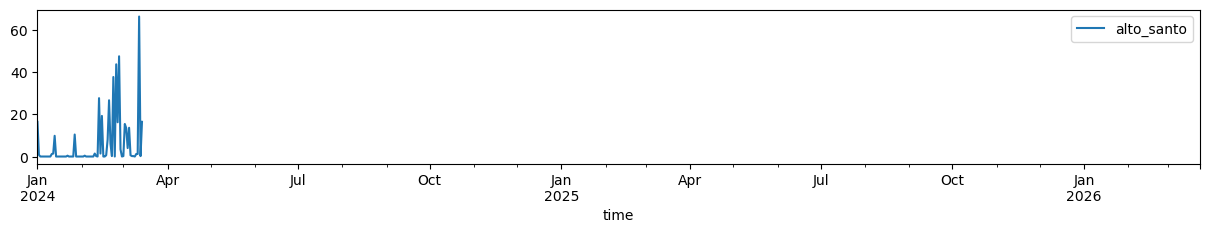

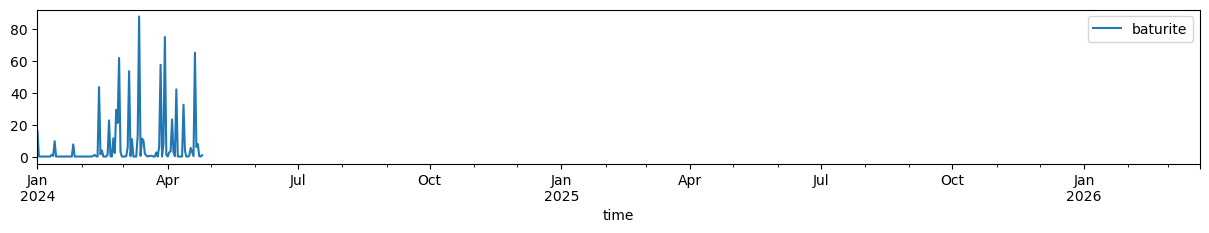

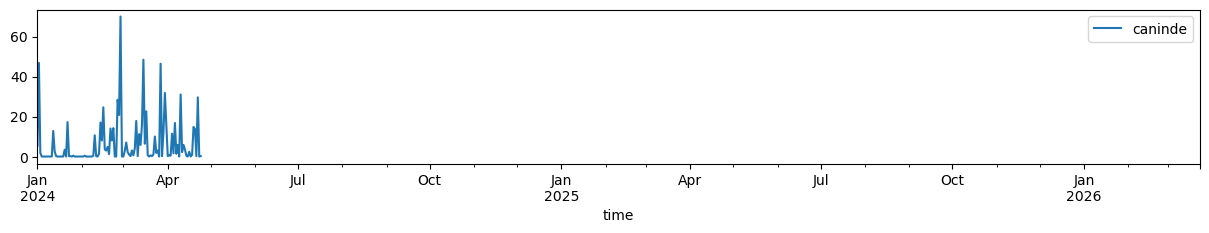

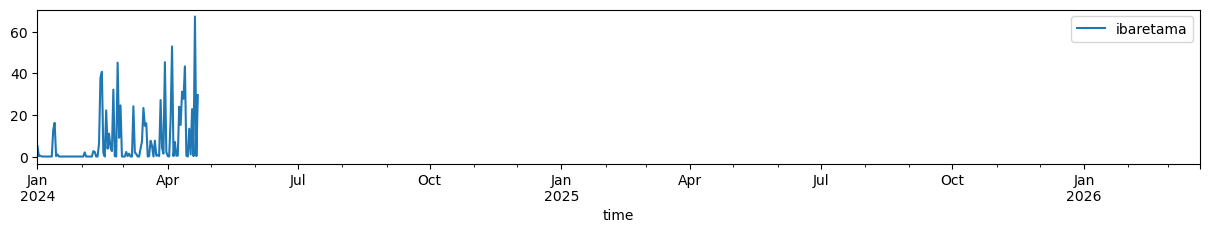

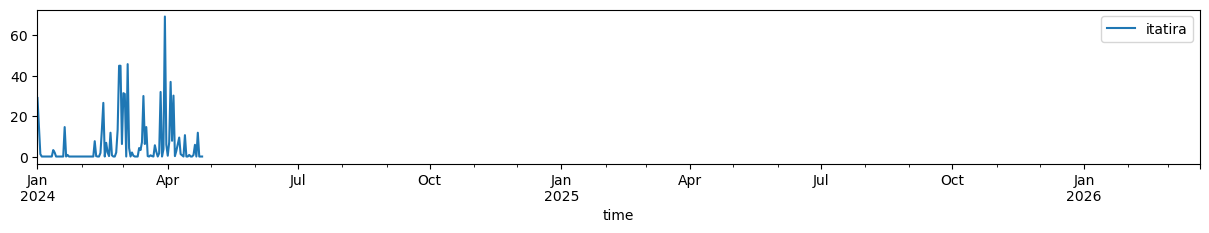

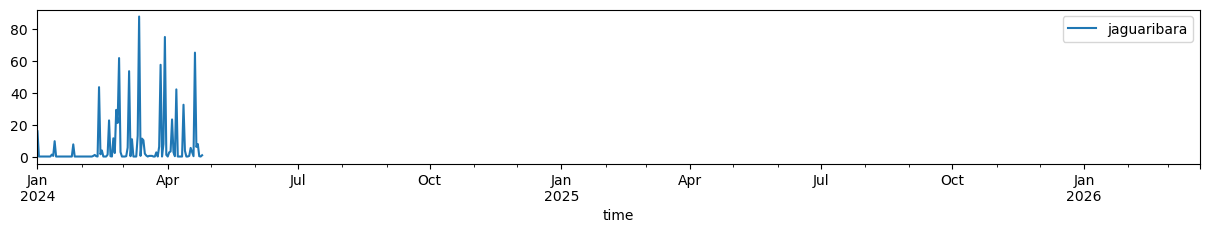

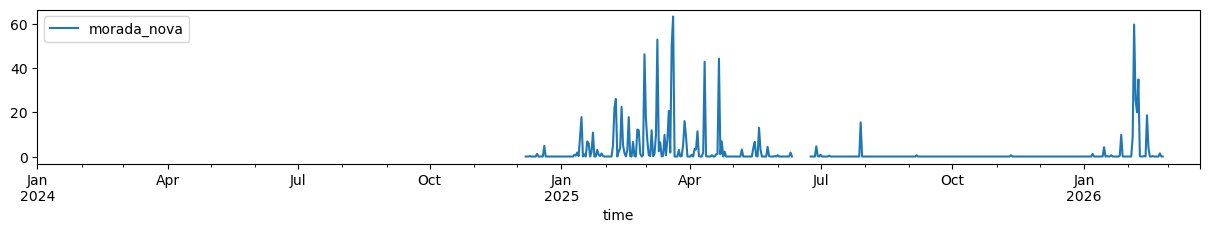

In [92]:
gauges.calc_distance_to_point((lat0, lon0))
close_gauges = gauges.metadata.loc[gauges.metadata.distance_to_point < 120]

min_steps_per_day = np.int64((24*6)*0.8)

print(f'minimal accepted steps per day (0.8): {min_steps_per_day}')

df_daily_acc = gauges.data.groupby(pd.Grouper(freq='1D')).sum(min_count=min_steps_per_day)

close_gauges_data = gauges.data.loc['2024':, close_gauges.index]

min_steps_per_day = np.int64((24*6)*0.8)

print(f'minimal accepted steps per day (0.8): {min_steps_per_day}')

df_daily_acc = gauges.data.groupby(pd.Grouper(freq='1D')).sum(min_count=min_steps_per_day)

for gauge in close_gauges.index:
    df_daily_acc.loc['2024':, gauge].plot(label=gauge, figsize=(15,2))
    ax = plt.gca()
    ax.legend()
    plt.show()


In [93]:
list_of_stations = close_gauges_data.columns.to_list()

def rad_vals_at_stations(ds, stations, gauges, varname='dBZ'):
    dfs = []
    for station in stations:
        lon, lat = gauges.get_coords_station(station)
        point = (lon, lat)
        df_rad = gutils.ds_to_df_at_point(ds, point)
        df_rad.rename(columns={varname: f'{station}_{varname}'}, inplace=True)
        dfs.append(df_rad)

    df_stations_rad = pd.concat(dfs, axis=1)
    return df_stations_rad

2024-01-02
['caninde', 'itatira']


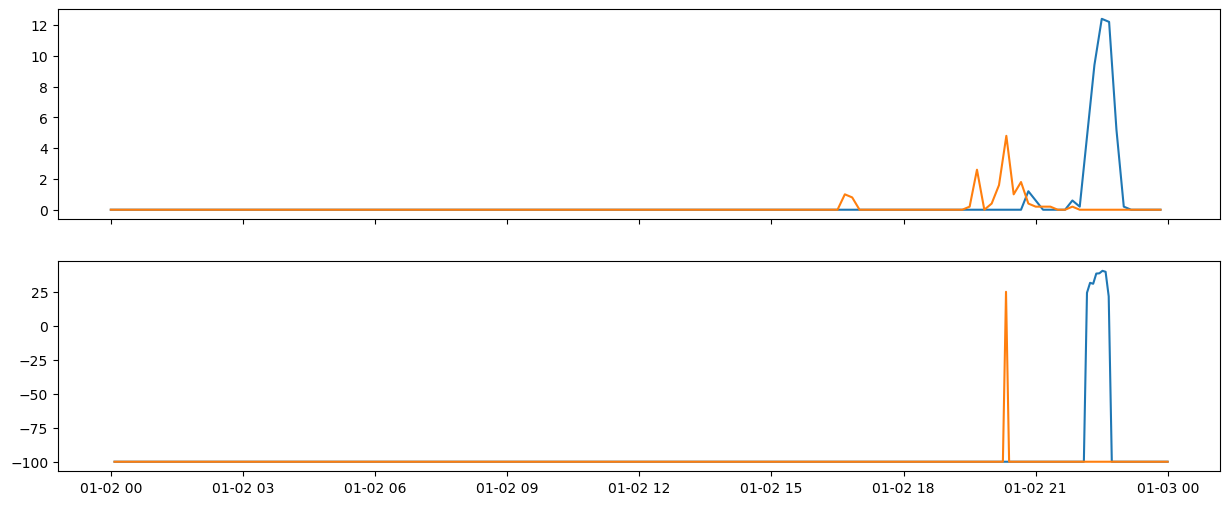

2024-02-13
['alto_santo', 'baturite', 'jaguaribara']


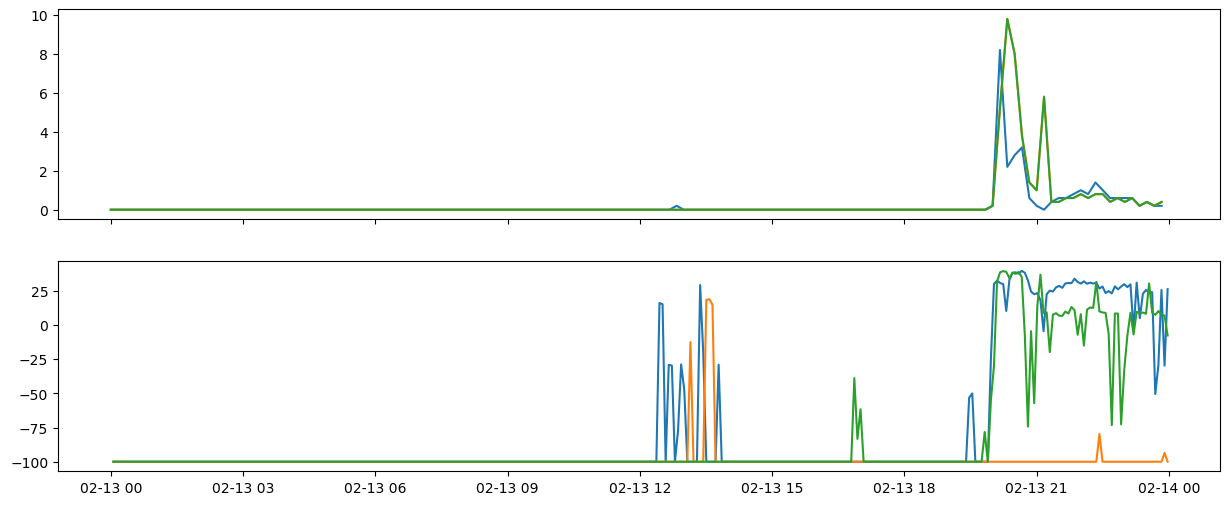

2024-02-14
['caninde', 'ibaretama']


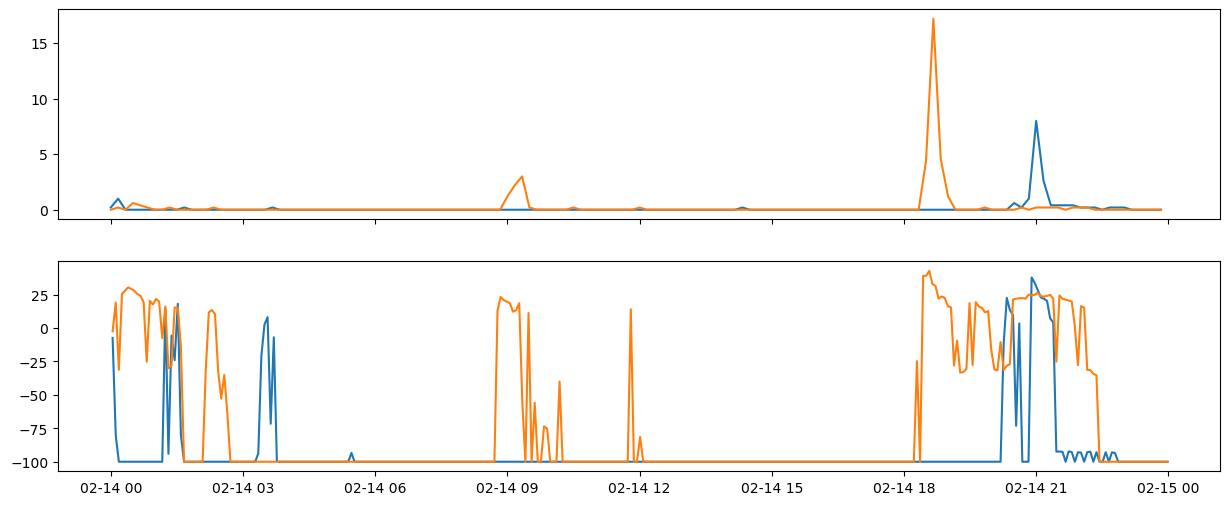

2024-02-15
['alto_santo', 'ibaretama']


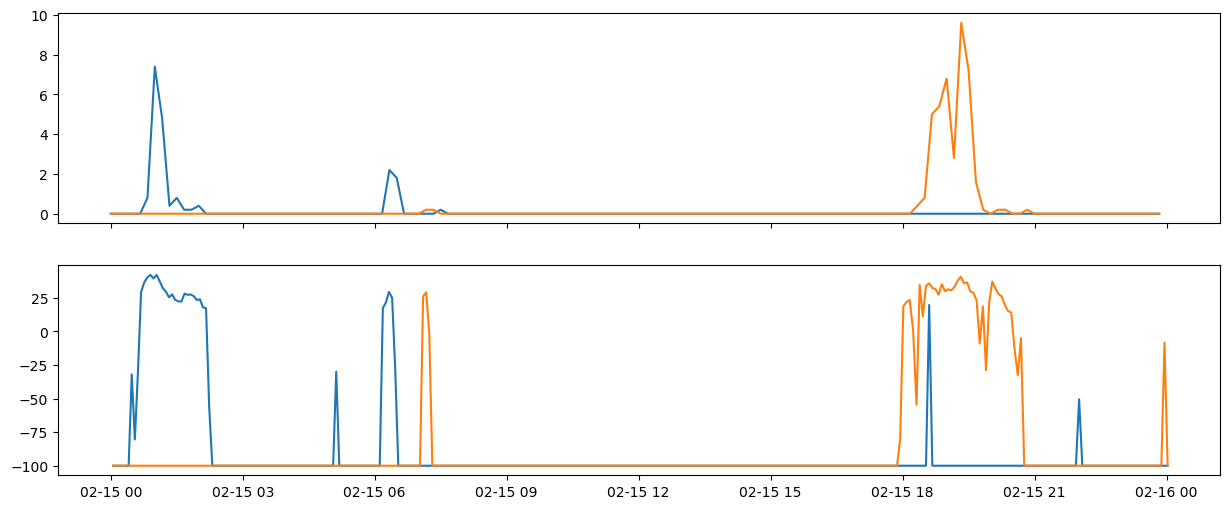

2024-02-23
['alto_santo', 'ibaretama']


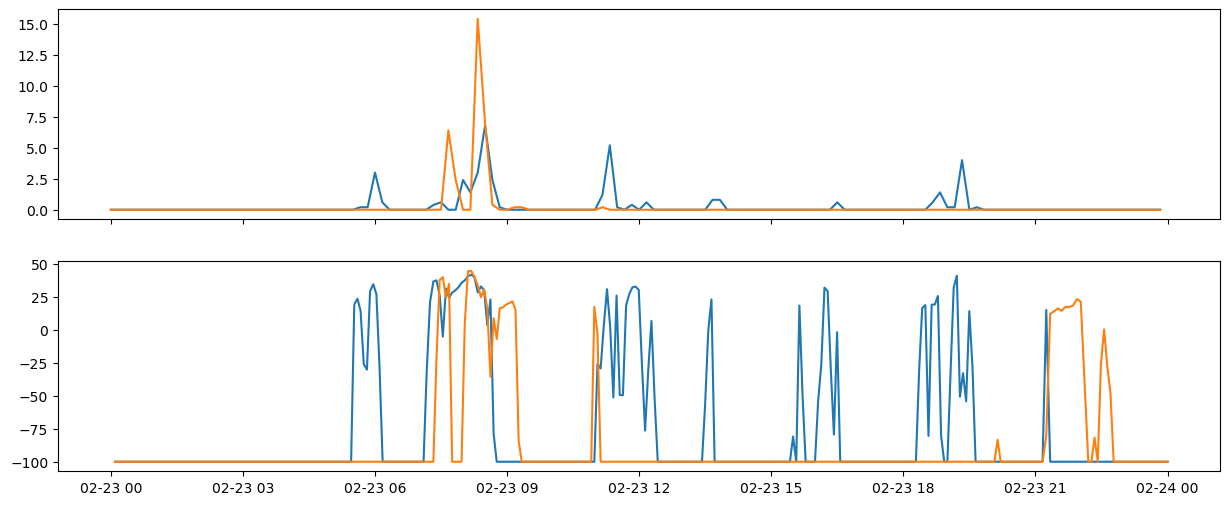

2024-02-25
['alto_santo', 'baturite', 'jaguaribara']


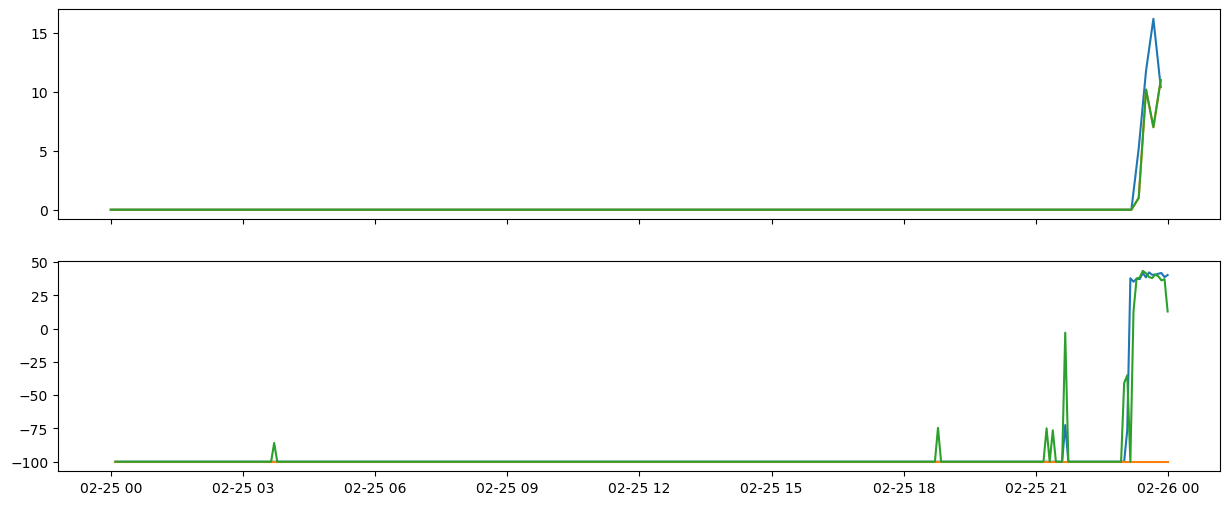

2024-02-26
['alto_santo', 'baturite', 'caninde', 'ibaretama', 'jaguaribara']


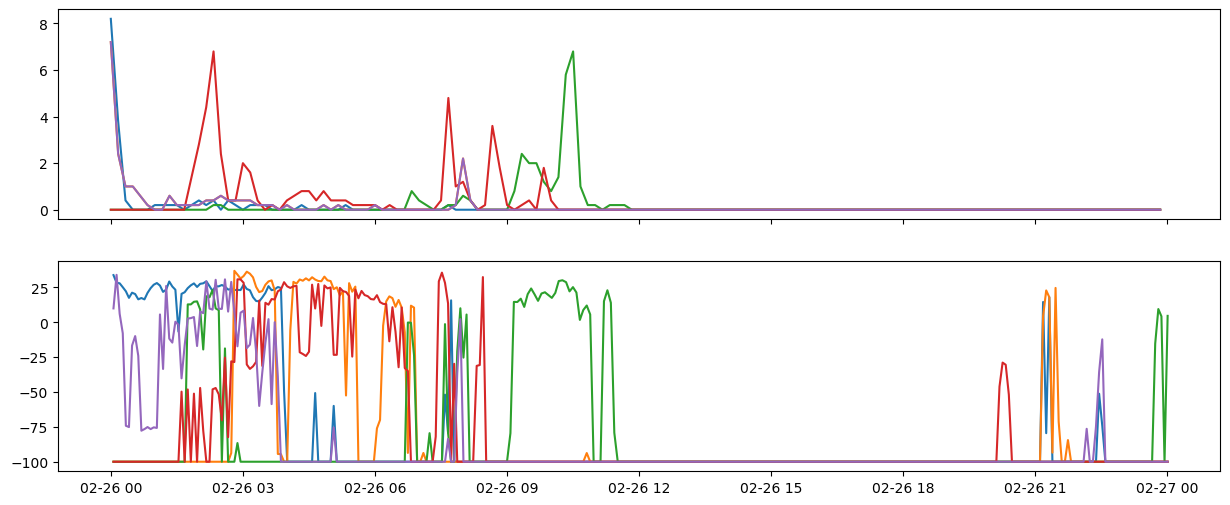

2024-02-27
['alto_santo', 'baturite', 'caninde', 'itatira', 'jaguaribara']


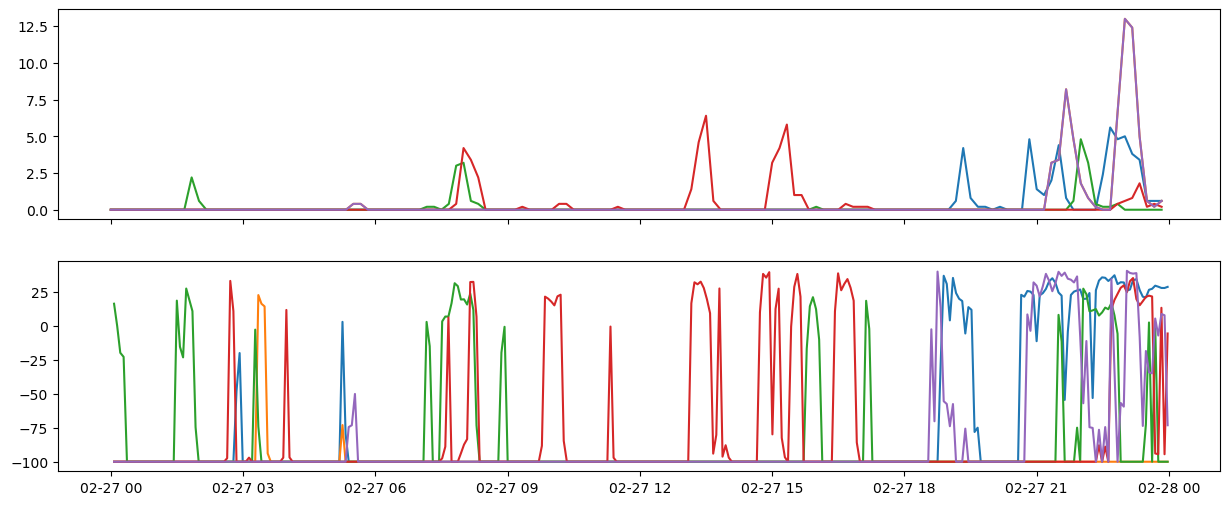

2024-02-28
['caninde', 'ibaretama', 'itatira']


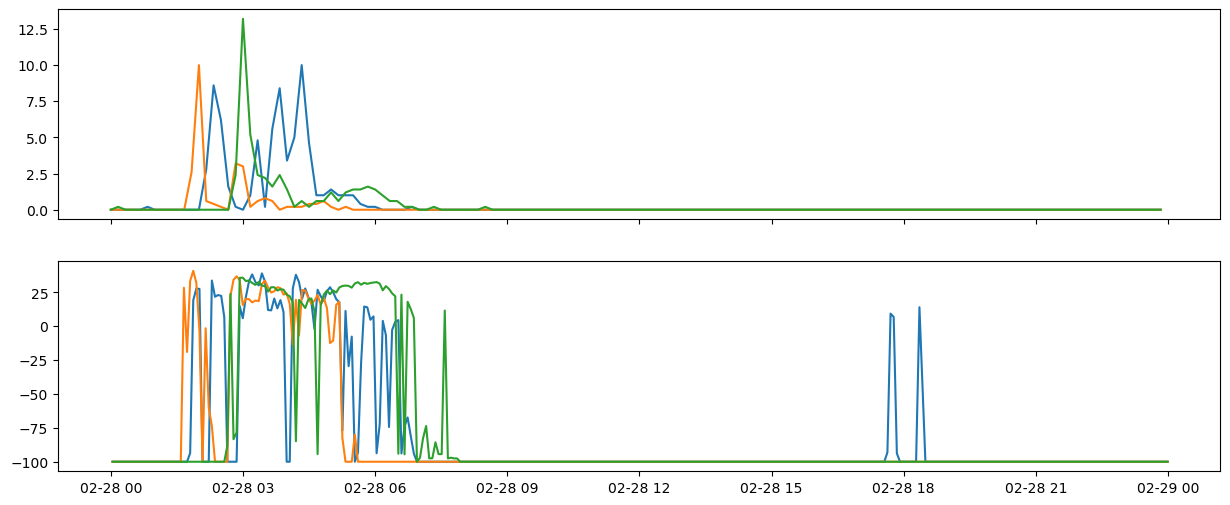

2024-03-01
['itatira']


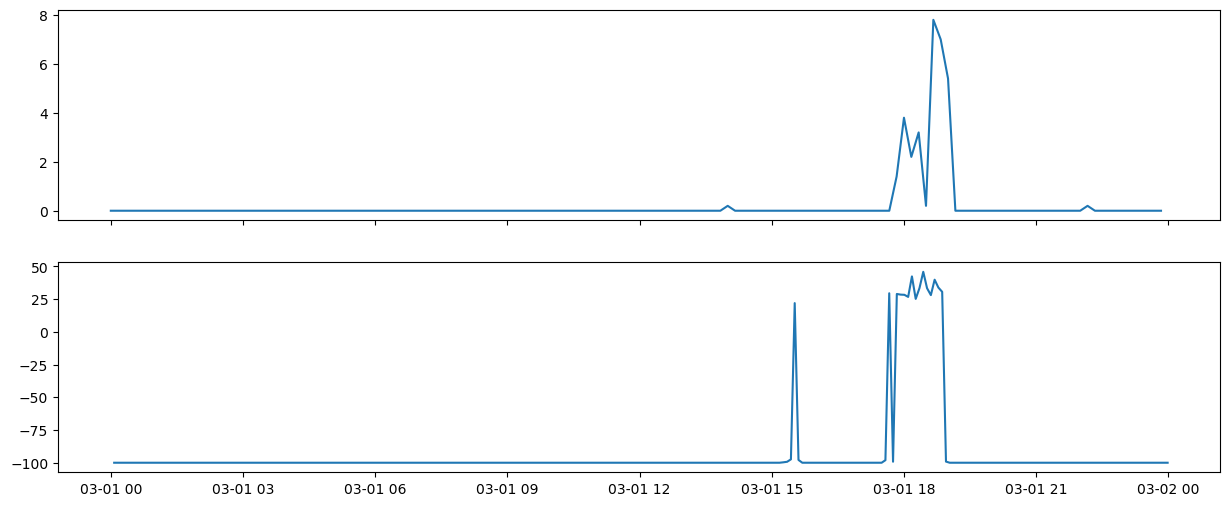

2024-03-02
['alto_santo', 'itatira']


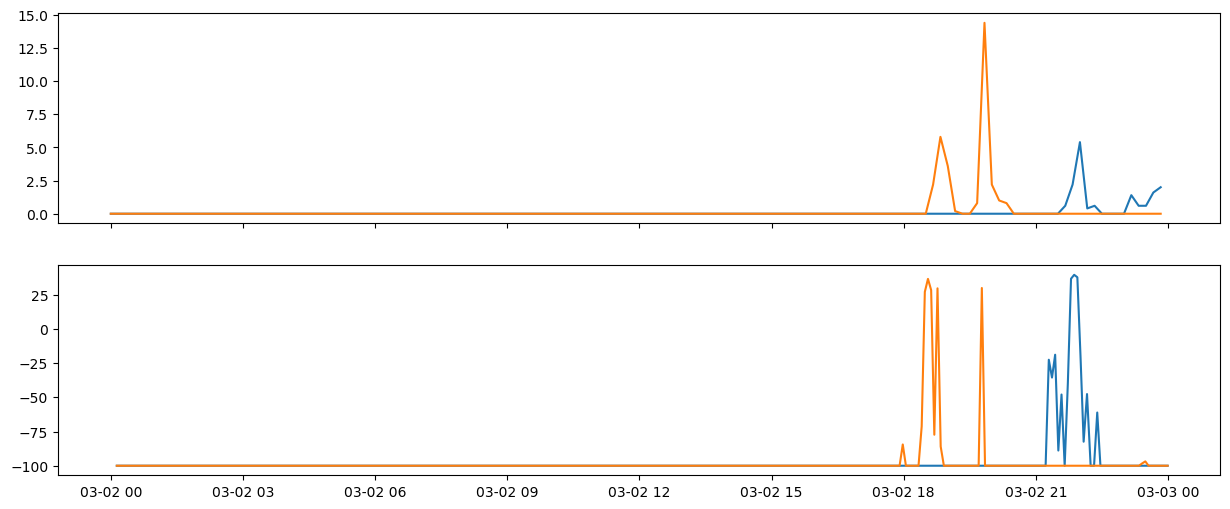

2024-03-04
['itatira']


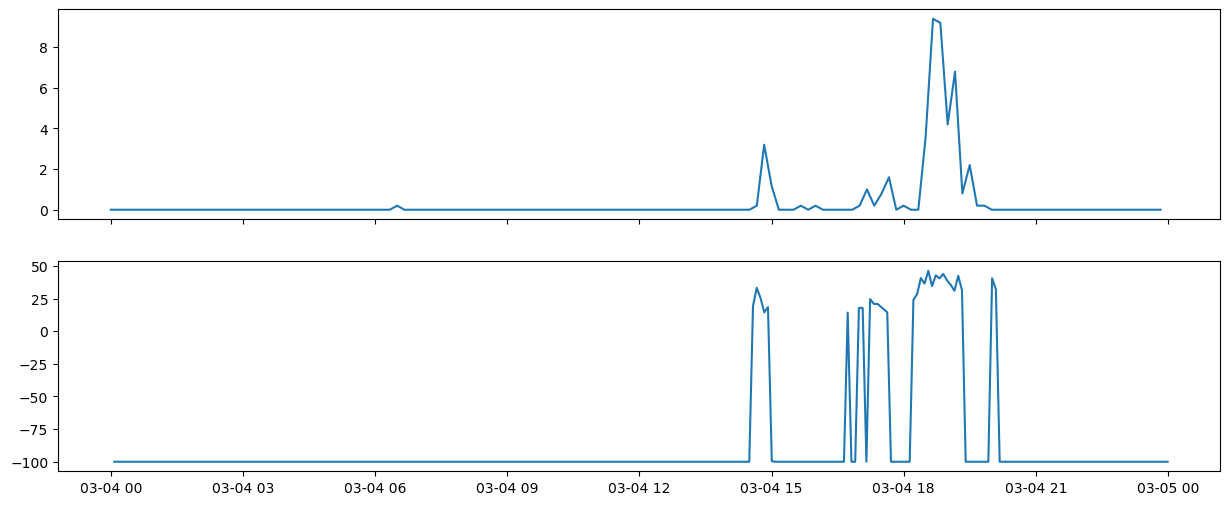

2024-03-05
['baturite', 'jaguaribara']


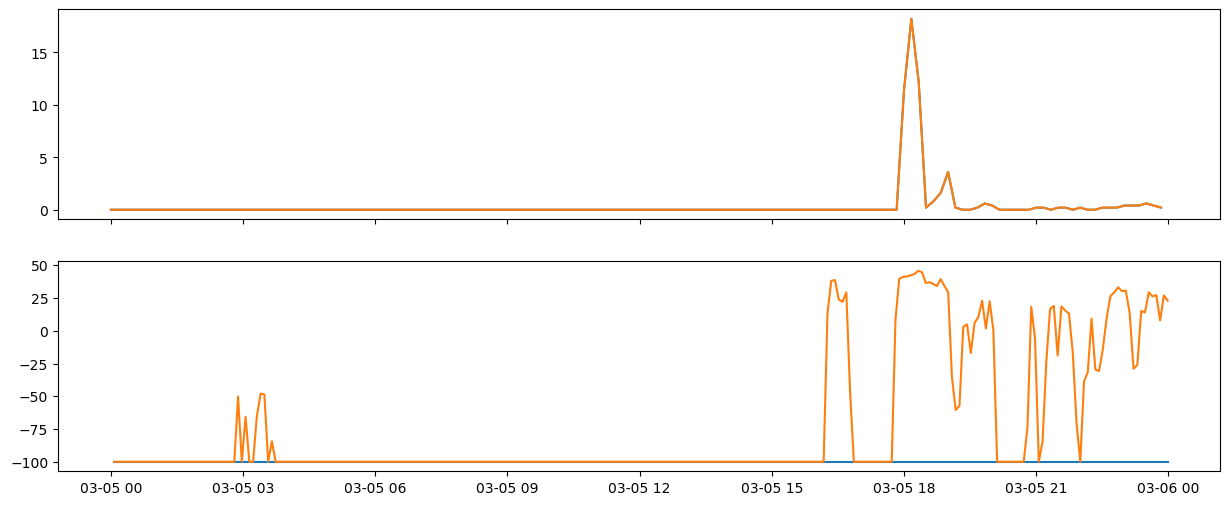

2024-03-12
['alto_santo', 'baturite', 'jaguaribara']


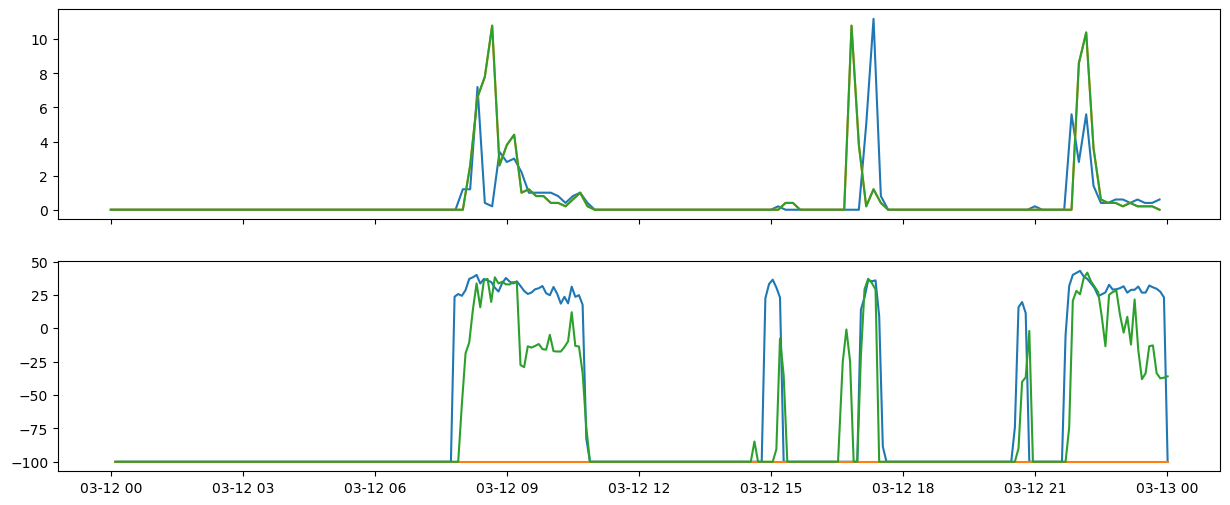

2024-03-15
['caninde', 'ibaretama', 'itatira']


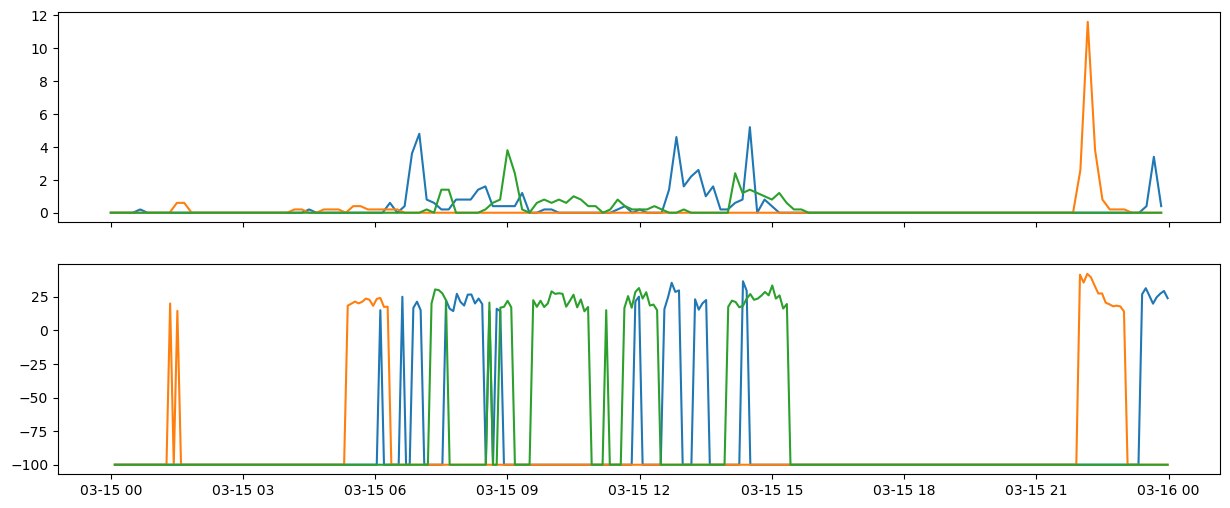

2024-03-27
['baturite', 'caninde', 'ibaretama', 'itatira', 'jaguaribara']


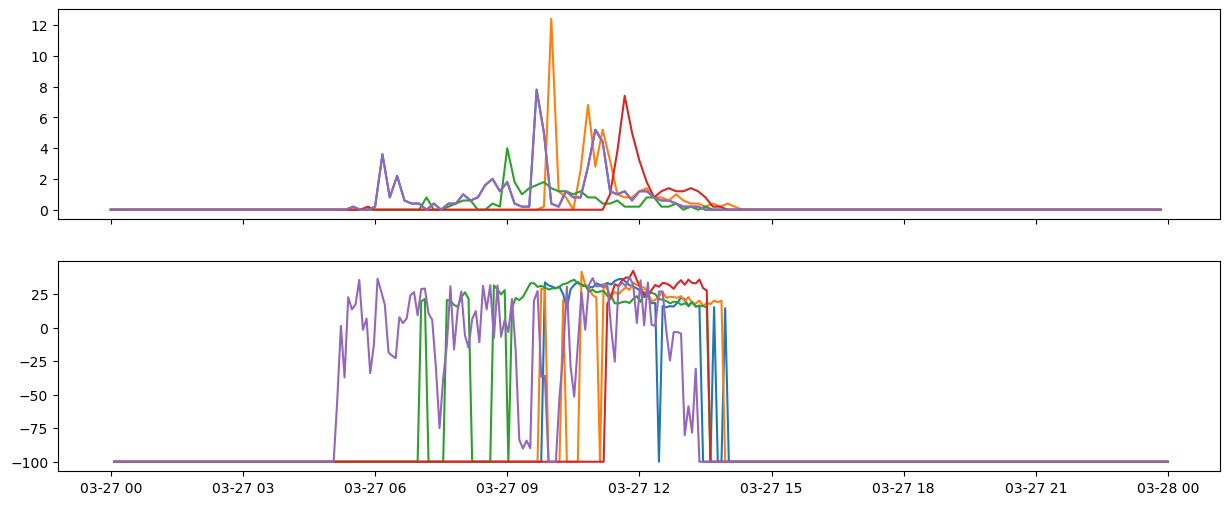

2024-03-30
['baturite', 'caninde', 'ibaretama', 'itatira', 'jaguaribara']


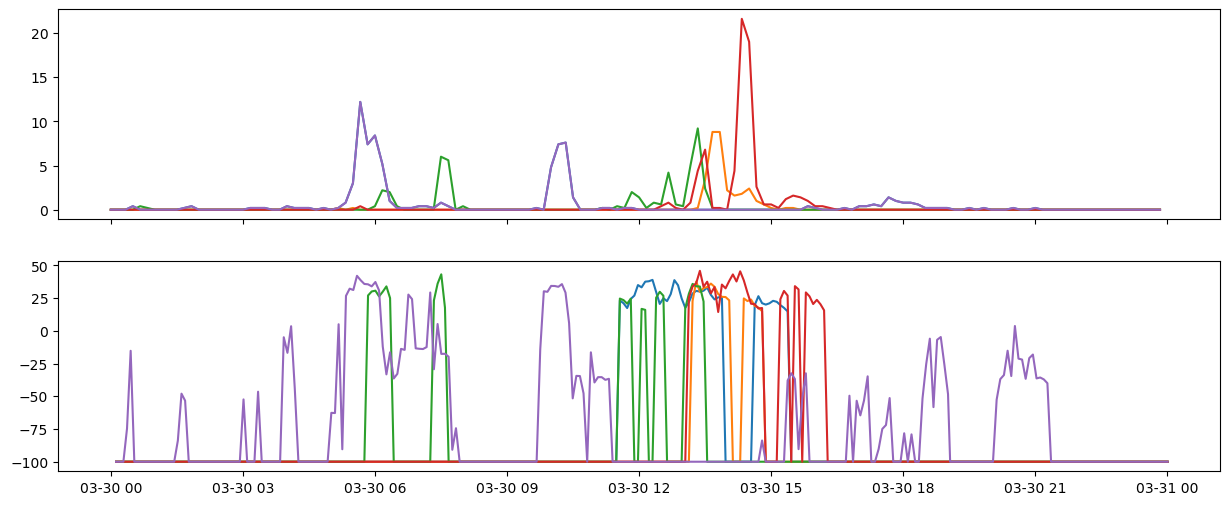

2024-04-03
['ibaretama', 'itatira']


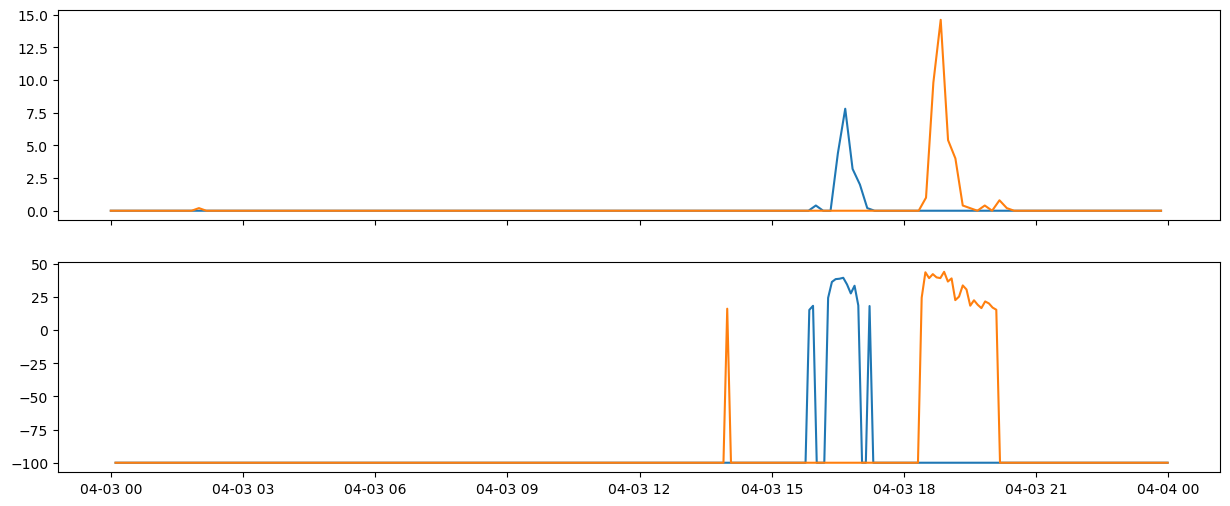

2024-04-04
['baturite', 'ibaretama', 'jaguaribara']


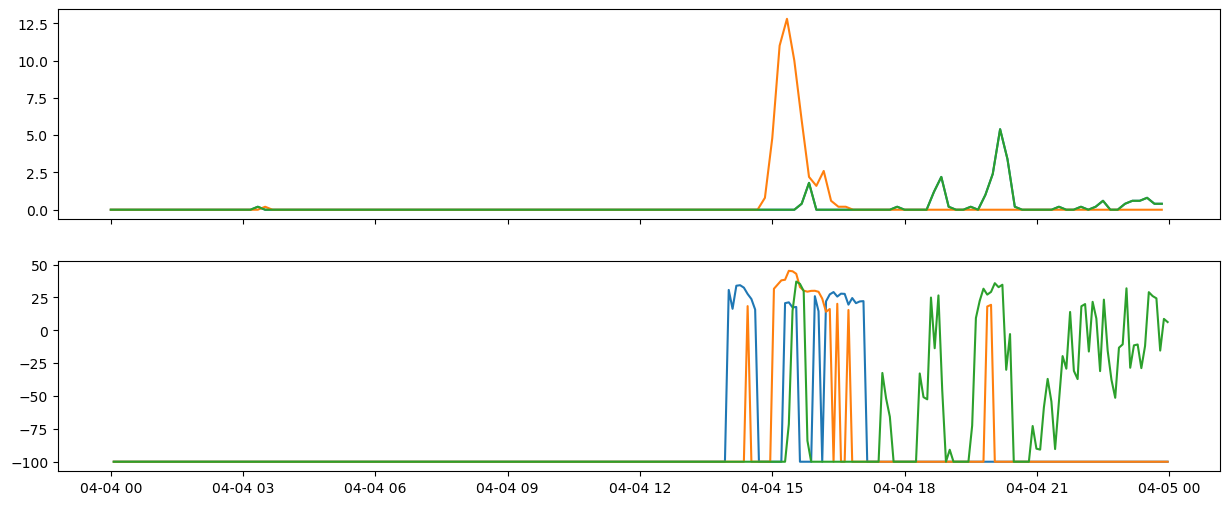

2024-04-05
['itatira']


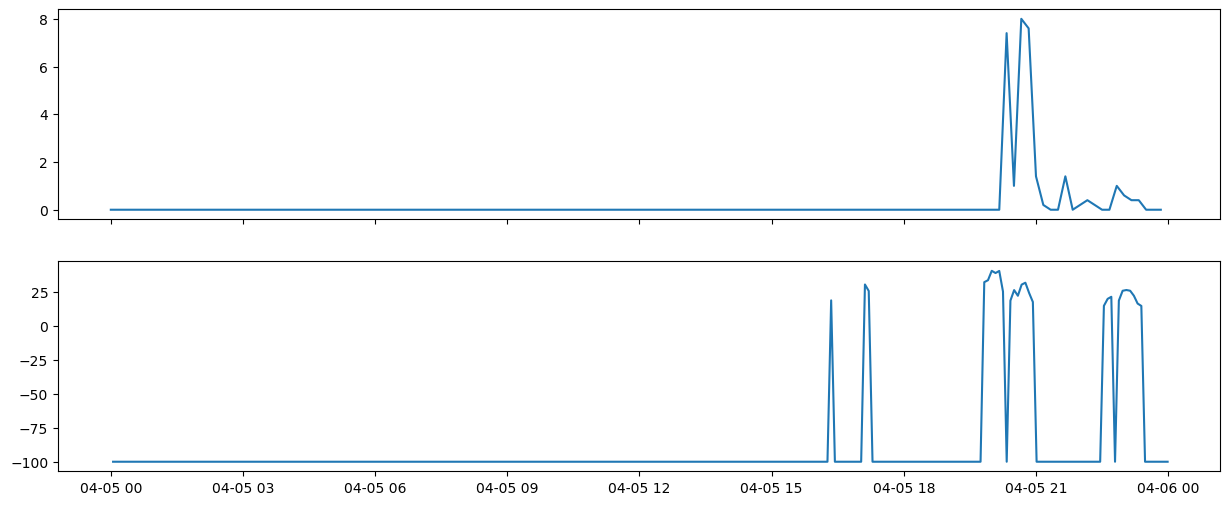

2024-04-07
['baturite', 'jaguaribara']


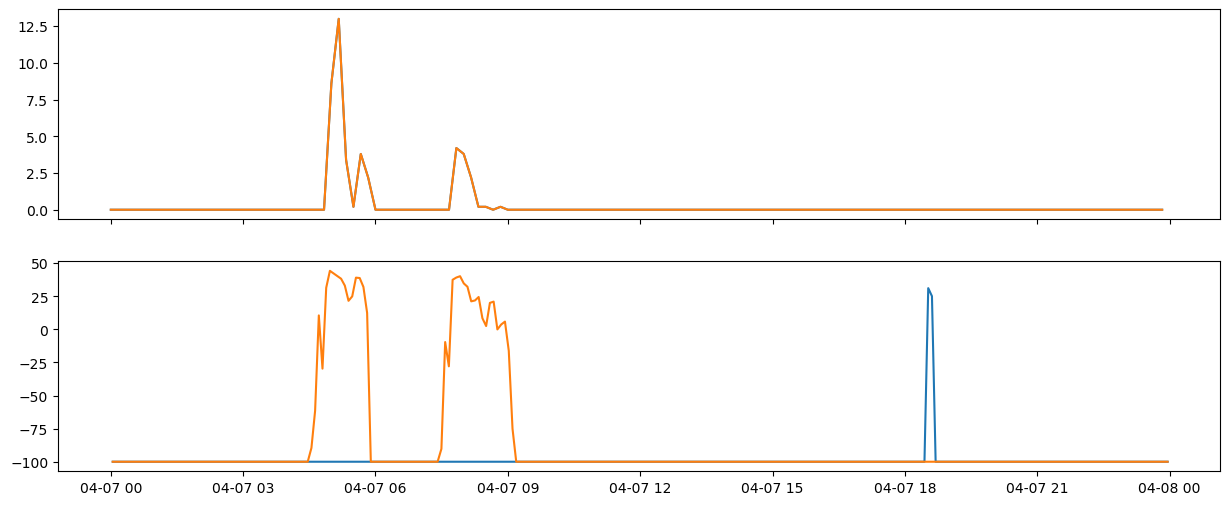

2024-04-10
['caninde', 'ibaretama']


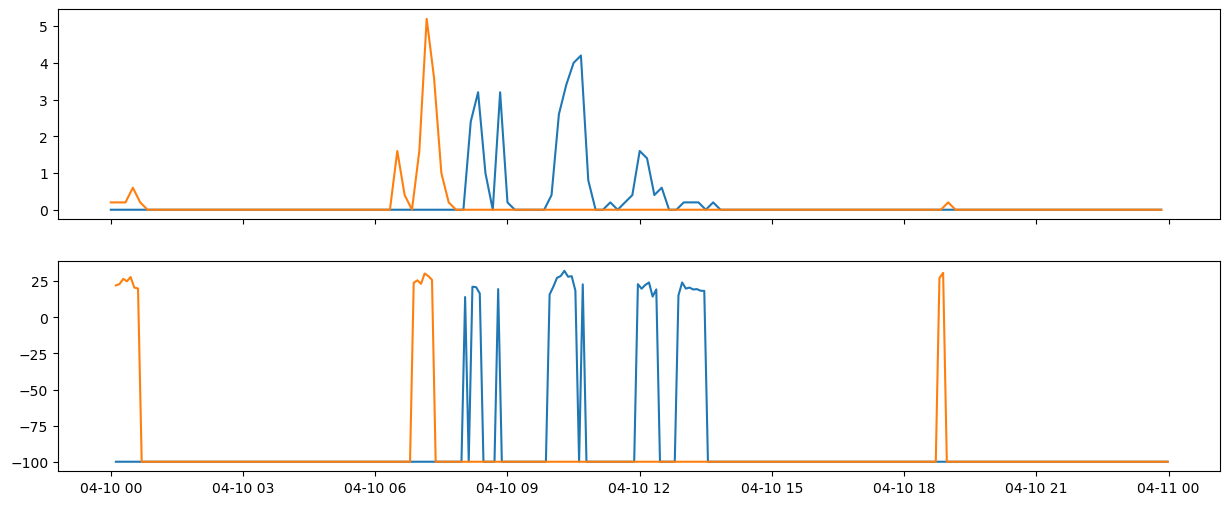

2024-04-11
['ibaretama']


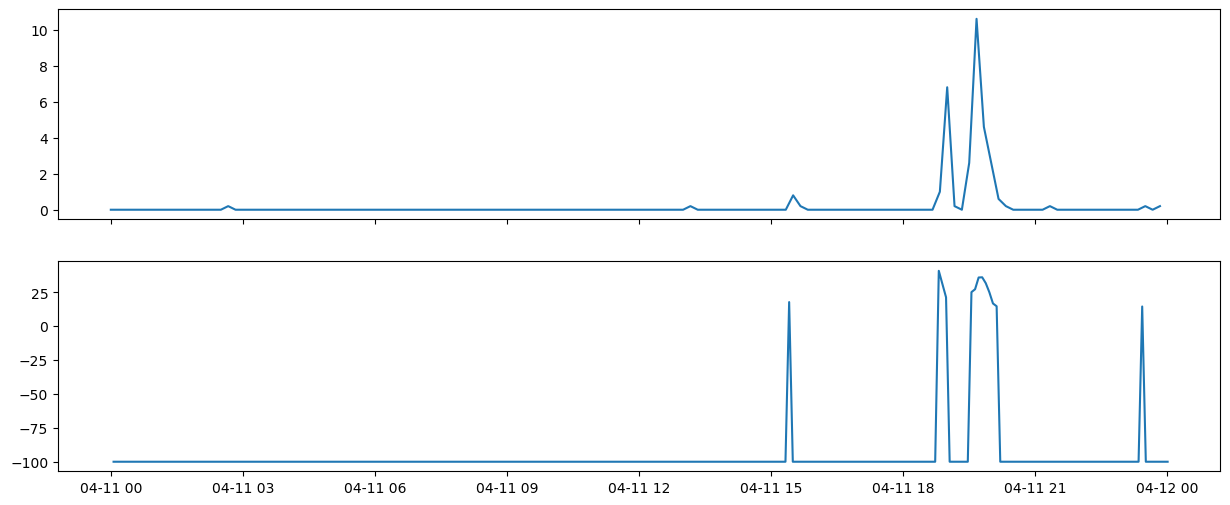

2024-04-12
['baturite', 'ibaretama', 'jaguaribara']


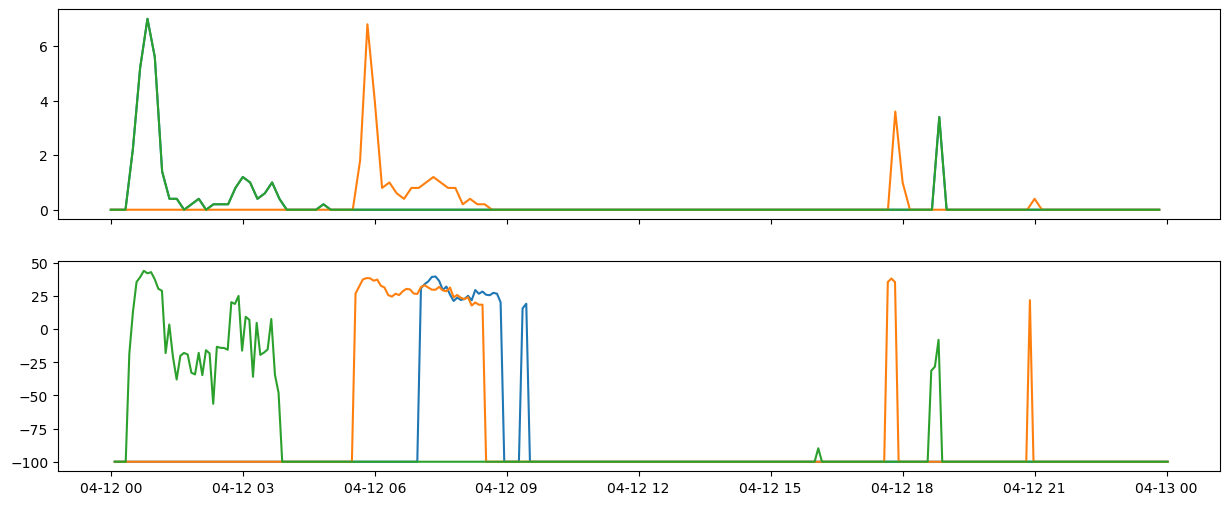

2024-04-13
['ibaretama']


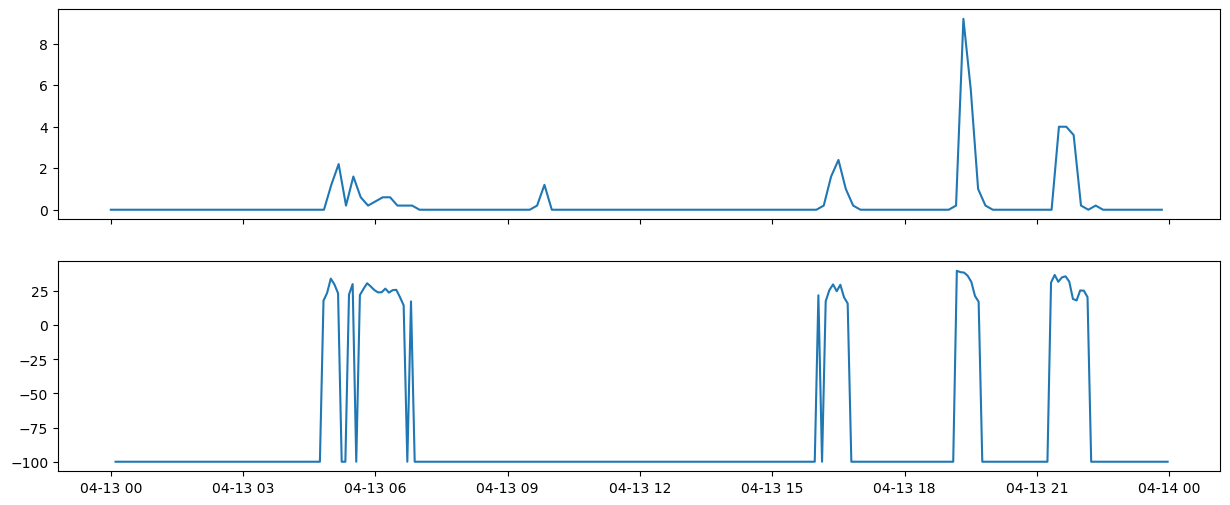

2024-04-20
['baturite', 'ibaretama', 'jaguaribara']


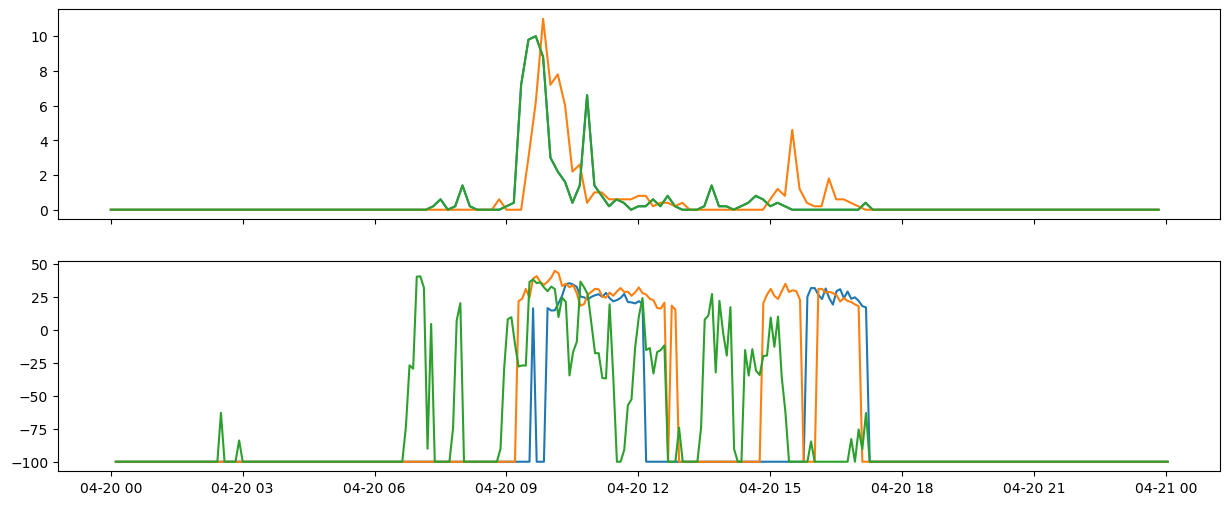

2025-02-28
['morada_nova']


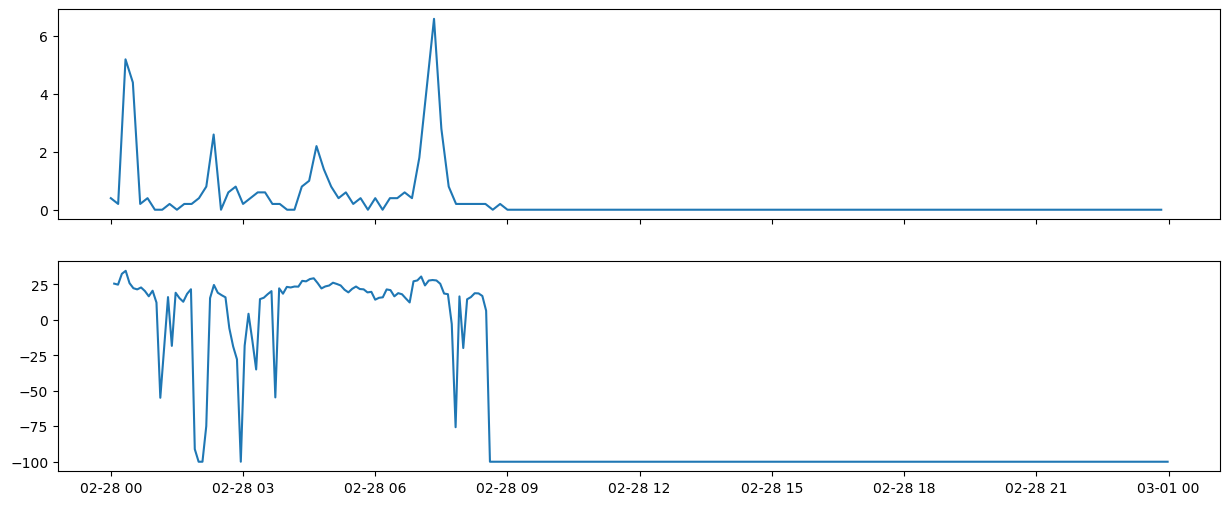

2025-03-09
['morada_nova']


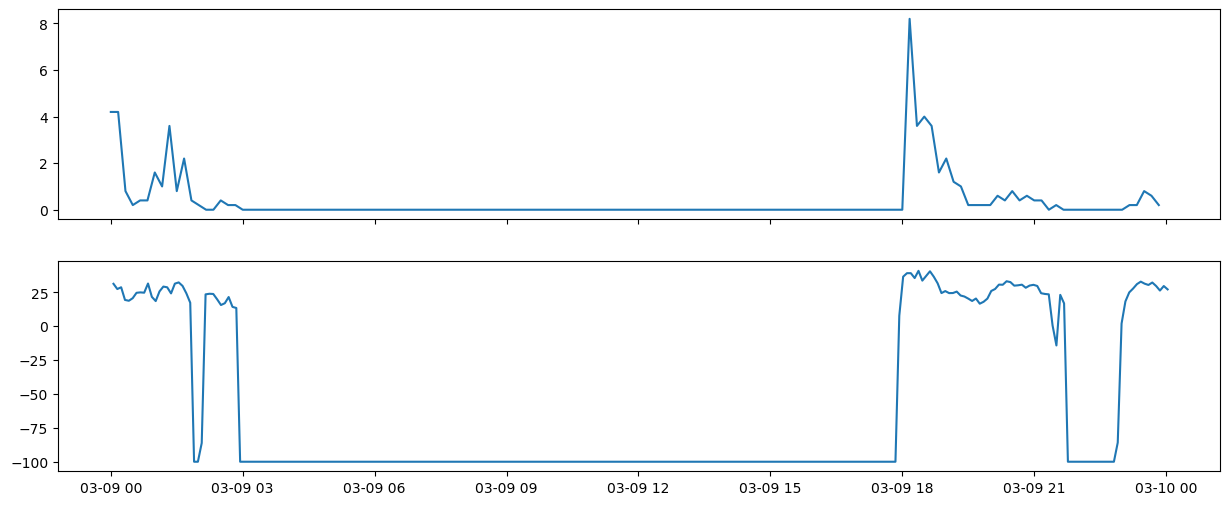

2025-03-19
['morada_nova']


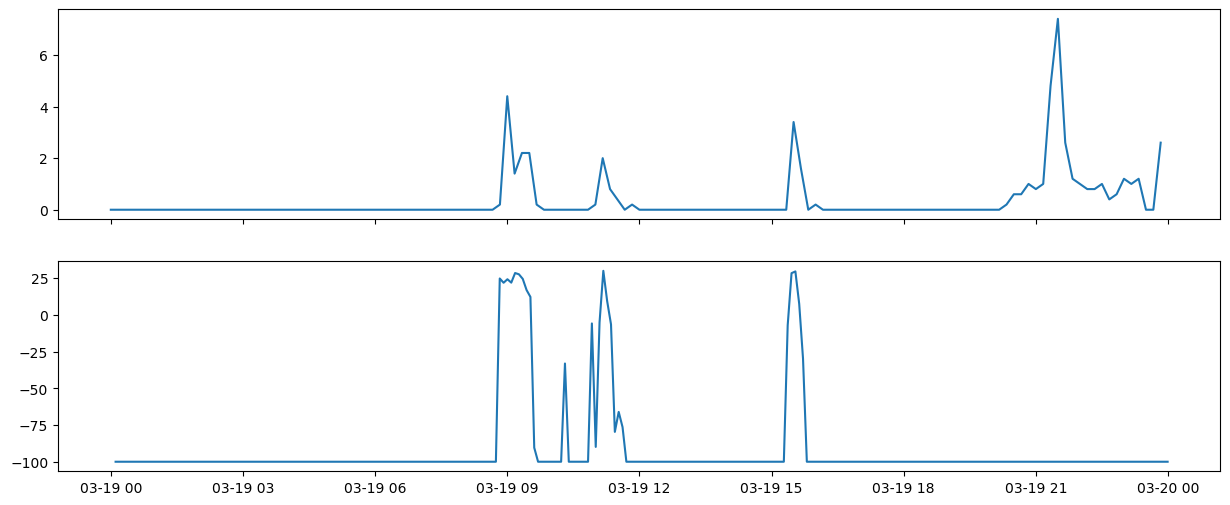

2025-03-20
['morada_nova']


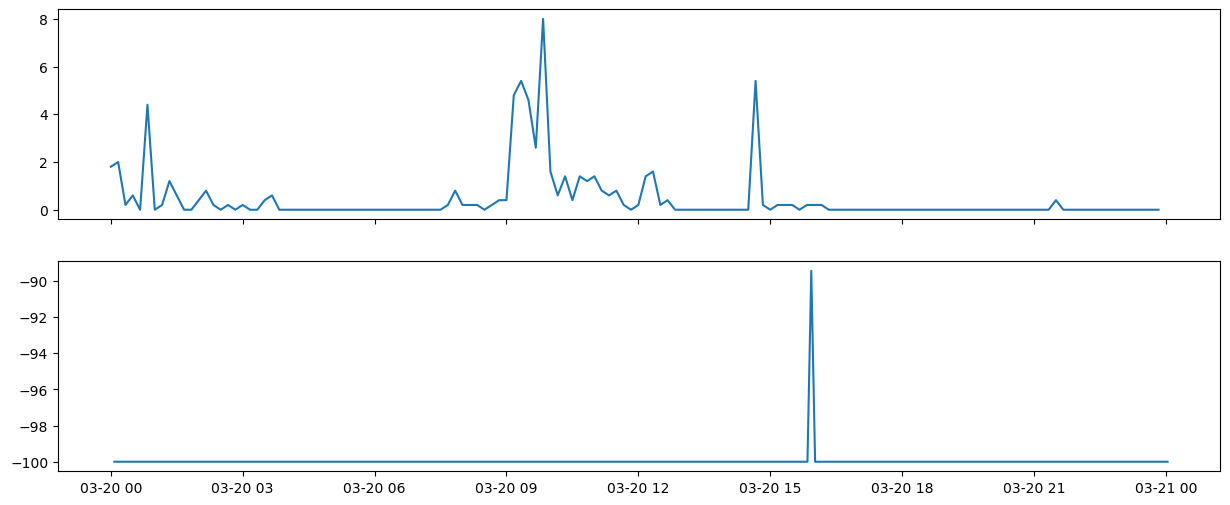

In [62]:
from pprint import pprint as pp

for day in df_fpaths_l1rad.index:
    print(day.date())
    date_str = str(day.date())
    ds = xr.open_dataset(df_fpaths_l1rad.loc[date_str, 'paths'])
    df_close = close_gauges_data.loc[date_str]
    stations = df_close.sum().loc[df_close.sum()>15].index.tolist()
    df_close = df_close.loc[:, stations]
    df_rad = rad_vals_at_stations(ds, stations, gauges, varname='dBZ').fillna(-100)
    print(stations)
    df_close.index = pd.to_datetime(df_close.index)
    df_rad.index = pd.to_datetime(df_rad.index)
    
    #fig, axes = plt.subplots(2,1, sharex=True, figsize=(15,8))

    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(15, 6))

    axes[0].plot(df_close.index, df_close)
    axes[1].plot(df_rad.index, df_rad)

    plt.show()

    #df_close.loc[:, stations].plot(ax=axes[0])
    #df_rad.plot(ax=axes[1])
    #plt.show()

In [94]:
dfs = {}

for day in df_fpaths_l1rad.index:
    date = str(day.date())
    ds = xr.open_dataset(df_fpaths_l1rad.loc[date, 'paths'])

    # Select active stations
    df_close = close_gauges_data.loc[date].copy()
    stations = df_close.columns[df_close.sum() > 15].tolist()
    df_close = df_close[stations]

    # Extract radar values
    df_rad = rad_vals_at_stations(
        ds, stations, gauges, varname='dBZ'
    ).fillna(-100)

    # Match nearest timestamps
    df_merged = pd.merge_asof(
        df_close.sort_index(),
        df_rad.sort_index(),
        left_index=True,
        right_index=True,
        direction='nearest',
        tolerance=pd.Timedelta('5min')
    )
    
    # Separate by station
    dfs[date] = {
        station: df_merged[[station, f'{station}_dBZ']]
            .set_axis(['gauge_measurement_mm', 'radar_measurement_dBZ'], axis=1)
        for station in stations
    }

<Axes: xlabel='time'>

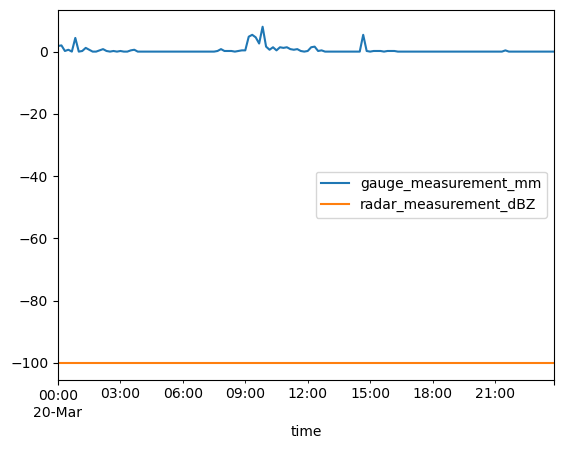

In [74]:
dfs['2025-03-20']['morada_nova'].plot()

In [95]:
dfs = {}

for day in df_fpaths_l1rad.index:
    date = str(day.date())
    ds = xr.open_dataset(df_fpaths_l1rad.loc[date, 'paths'])

    # Select active stations
    df_close = close_gauges_data.loc[date].copy()
    stations = df_close.columns[df_close.sum() > 15].tolist()
    df_close = df_close[stations]
    if not stations:
        ds.close()
        continue

    # Radar reflectivity at stations
    df_rad = rad_vals_at_stations(
        ds, stations, gauges, varname='dBZ'
    ).replace(-100, np.nan)
    ds.close()

    # Derived variables
    df_ref = l2rad.calc_refl_from_rate(df_close * 6).add_suffix('_ref')
    df_rate = l2rad.calc_rate_from_refl(df_rad).add_suffix('_rate')

    # Combine and match timestamps
    df_gauge = df_close.join(df_ref)
    df_radar = df_rad.join(df_rate)

    df_merged = pd.merge_asof(
        df_gauge.sort_index(),
        df_radar.sort_index(),
        left_index=True,
        right_index=True,
        direction='nearest',
        tolerance=pd.Timedelta('5min')
    )

    # One DataFrame per station, per day
    dfs[date] = {
        station: df_merged[
            [station, f'{station}_ref', f'{station}_dBZ', f'{station}_dBZ_rate']
        ].set_axis([
            'gauge_measurement_mm',
            'ref_from_gauge_dBZ',
            'radar_measurement_dBZ',
            'rate_from_rad_mmh'
        ], axis=1)
        for station in stations
    }

In [99]:
dfs

{'2024-01-02': {'caninde':                      gauge_measurement_mm  ref_from_gauge_dBZ  \
  time                                                            
  2024-01-02 00:00:00                   0.0            -40.9897   
  2024-01-02 00:10:00                   0.0            -40.9897   
  2024-01-02 00:20:00                   0.0            -40.9897   
  2024-01-02 00:30:00                   0.0            -40.9897   
  2024-01-02 00:40:00                   0.0            -40.9897   
  ...                                   ...                 ...   
  2024-01-02 23:10:00                   0.0            -40.9897   
  2024-01-02 23:20:00                   0.0            -40.9897   
  2024-01-02 23:30:00                   0.0            -40.9897   
  2024-01-02 23:40:00                   0.0            -40.9897   
  2024-01-02 23:50:00                   0.0            -40.9897   
  
                       radar_measurement_dBZ  rate_from_rad_mmh  
  time                             

In [121]:
station = 'alto_santo'

df_station = pd.concat([
    daily[station]
    for daily in dfs.values()
    if station in daily
]).sort_index()

In [122]:
df_station.groupby(pd.Grouper(freq='1D')).corr().dropna().loc[:, 'rate_from_rad_mmh'].unstack().loc[:, 'gauge_measurement_mm']

time
2024-02-13    0.451324
2024-02-15    0.591780
2024-02-23    0.114726
2024-02-25    0.721802
2024-02-26    0.737519
2024-02-27    0.532219
2024-03-02    0.145428
2024-03-12    0.487750
Name: gauge_measurement_mm, dtype: float64

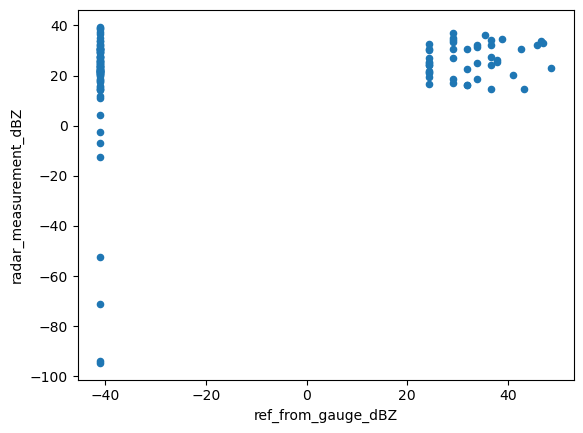

In [120]:
df_station.plot.scatter('ref_from_gauge_dBZ', 'radar_measurement_dBZ')
ax = plt.gca()


In [68]:
df_merged = pd.merge_asof(
    l2rad.calc_refl_from_rate((df_close*6).sort_index()),
    df_rad.sort_index(),
    left_index=True,
    right_index=True,
    direction='nearest',
    tolerance=pd.Timedelta('5min')
)

<Axes: xlabel='time'>

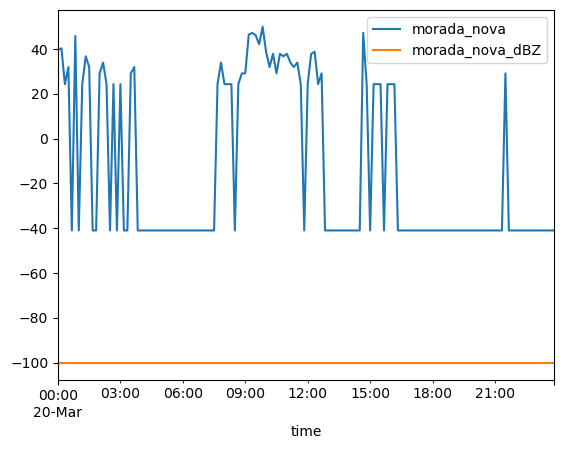

In [69]:
df_merged.plot()

In [63]:
df_close

id,morada_nova
time,
2025-03-20 00:00:00,1.8
2025-03-20 00:10:00,2.0
2025-03-20 00:20:00,0.2
2025-03-20 00:30:00,0.6
2025-03-20 00:40:00,0.0
...,...
2025-03-20 23:10:00,0.0
2025-03-20 23:20:00,0.0
2025-03-20 23:30:00,0.0


In [64]:
df_rad

,morada_nova_dBZ
time,
2025-03-20 00:04:43.500,-100.0
2025-03-20 00:09:57.500,-100.0
2025-03-20 00:15:12.000,-100.0
2025-03-20 00:20:26.500,-100.0
2025-03-20 00:25:38.500,-100.0
...,...
2025-03-20 23:41:28.000,-100.0
2025-03-20 23:46:41.500,-100.0
2025-03-20 23:51:55.500,-100.0


In [60]:
df_close

id,alto_santo,baturite,caninde,ibaretama,itatira,jaguaribara,morada_nova
time,,,,,,,
2025-03-20 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.8
2025-03-20 00:10:00,NaN,NaN,NaN,NaN,NaN,NaN,2.0
2025-03-20 00:20:00,NaN,NaN,NaN,NaN,NaN,NaN,0.2
2025-03-20 00:30:00,NaN,NaN,NaN,NaN,NaN,NaN,0.6
2025-03-20 00:40:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0
...,...,...,...,...,...,...,...
2025-03-20 23:10:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-03-20 23:20:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2025-03-20 23:30:00,NaN,NaN,NaN,NaN,NaN,NaN,0.0
